<a href="https://colab.research.google.com/github/Rapcher1/digital_twin_atf/blob/dev/01_probability_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.1: Probability & Neural Networks for Digital Twins

## Learning Objectives
- Understand how AI makes predictions using probability
- Learn the basics of neural networks
- Apply these concepts to building a digital twin

## Digital Twin Context
A **digital twin** is a virtual representation of a physical entity (person, object, system). In this series, we'll build a digital twin that can:
- Predict behaviors and preferences
- Understand and respond to language
- Learn from interactions

## Key Insight
> "AI isn't thinking; it's predicting the next number."

This applies to everything from weather prediction to language generation!

---
## Part 1: Probability Foundations

Let's start with the basics: How does AI make predictions?

In [14]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


### 1.1 Simple Prediction: Next Number

Let's simulate a digital twin predicting your next action based on historical data.

Activity Probabilities:
  Sleep: 20.00%
  Work: 40.00%
  Exercise: 13.33%
  Social: 13.33%
  Leisure: 13.33%


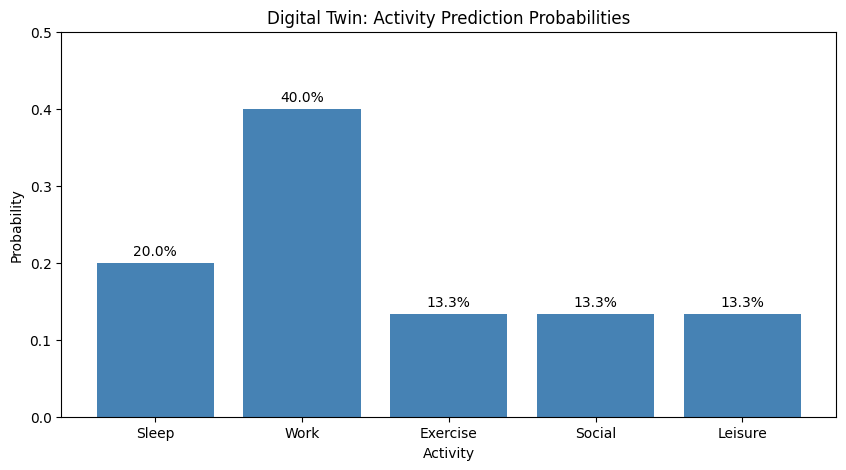

In [16]:
from collections import Counter
import matplotlib.pyplot as plt

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
probs = calculate_probabilities(historical_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilities:")
for activity, prob in sorted(probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()

### 🎯 Exercise 1.1 (Easy): Understanding Probabilities

**Task**: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

**Questions**:
1. Which activity has the highest probability?
2. What does this tell you about the pattern in your data?
3. How would adding more data points affect the predictions?

In [19]:
# YOUR CODE HERE
# Create your own sequence of activities (14 values)

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure
my_activities = [0, 1, 1, 1, 1, 3, 2, 0, 1, 1, 1, 1, 3, 4]  # Replace with your pattern

# Calculate and visualize
my_probs = calculate_probabilities(my_activities)

# YOUR ANALYSIS HERE (write answers as comments)
# 1. Highest probability activity:
# 2. Pattern insight:
# 3. Impact of more data:

# 1. Highest probability activity: Work (1), at 57.1% (8 out of 14 days) — it dominates
#    because of two 4-day work streaks.
# 2. Pattern insight: The sequence repeats a 7-day cycle twice (Sleep, 4x Work, Social,
#    Exercise), suggesting a weekly routine where work dominates weekdays and Social/
#    Exercise mark the transition into the weekend. A plain frequency count captures
#    *how often* each activity happens but not this *order* or cyclical structure.
# 3. Impact of more data: With only 14 points, each activity's probability is coarse —
#    one extra Exercise day would roughly double its estimate (1/14 → 2/14). More
#    historical data (e.g. several months) would smooth out these estimates and let
#    rarer activities (Exercise, Leisure) be measured more reliably, while also
#    revealing whether the weekly cycle actually holds or varies over time.

### 1.2 Conditional Probability: Context Matters

What if predictions depend on previous activities? This is where context comes in!

In [20]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%

After Work:
  → Exercise: 33.33%
  → Social: 33.33%
  → Leisure: 33.33%

After Exercise:
  → Work: 100.00%

After Social:
  → Work: 100.00%

After Leisure:
  → Sleep: 100.00%



### 🎯 Exercise 1.2 (Intermediate): Markov Chain Prediction

**Task**: Build a simple predictor that uses conditional probabilities to predict the next activity.

**Challenge**: What happens after "Work"? Which activity is most likely?

In [26]:
def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.

    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities

    Returns:
        int: Most likely next activity
    """
    # YOUR CODE HERE
    # Hint: Find the activity with maximum probability given current_activity
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]
    # Find the activity (key) with the highest probability (value)
    predicted_activity = max(next_probs, key=next_probs.get)
    return predicted_activity



# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")

# BONUS: Predict a sequence of 5 activities starting from "Work"
sequence = [current]
for _ in range(5):
  next_activity = predict_next_activity(sequence[-1], cond_probs)
  if next_activity is None:
      break
  sequence.append(next_activity)

print("Predicted sequence:", [activity_names[a] for a in sequence])


After Work, most likely next: Exercise
Predicted sequence: ['Work', 'Exercise', 'Work', 'Exercise', 'Work', 'Exercise']


---
## Part 2: Neural Networks Basics

Now let's see how neural networks learn to make predictions!

### 2.1 The Perceptron: Building Block of Neural Networks

A perceptron is the simplest neural network - it takes inputs, applies weights, and produces an output.

In [6]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """
    Simple perceptron implementation.

    Args:
        inputs: Array of input values
        weights: Array of weights
        bias: Bias term

    Returns:
        float: Output after activation
    """
    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will exercise based on features
# Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.3, 0.5, 0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of exercising: {prediction:.2%}")
print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")

Probability of exercising: 95.93%
Prediction: Will exercise


### 🎯 Exercise 2.1 (Easy): Feature Engineering

**Task**: Modify the features and observe how the prediction changes.

**Questions**:
1. What happens when sleep hours decrease to 4?
2. What if free time increases to 4 hours?
3. Which feature seems to have the most impact based on the weights?

In [30]:
# YOUR CODE HERE
# Test different feature combinations

test_cases = [
    np.array([4, 2, 0.8]),  # Low sleep
    np.array([7, 4, 0.8]),  # More free time
    np.array([7, 2, 0.3]),  # Low energy
]

case_labels = [
    "Low sleep      ",
    "More free time ",
    "Low energy     "
]

# Extract scalar from prediction array if it is a numpy array
baseline_pred = prediction.item() if isinstance(prediction, np.ndarray) else prediction

# Test each case and analyze results
print(f"Baseline [7, 2, 0.8]: {baseline_pred:.2%} →  "
      f"{'Will exercise' if baseline_pred > 0.5 else 'Will not exercise'}\n")

for label, features in zip(case_labels, test_cases):
  result = perceptron(features, weights, bias)
  outcome = 'Will exercise' if result > 0.5 else 'Will not exercise'
  print(f"{label} {features}: {result:.2%} →  {outcome}")

Baseline [7, 2, 0.8]: 22.70% →  Will not exercise

Low sleep       [4.  2.  0.8]: 90.55% →  Will exercise
More free time  [7.  4.  0.8]: 98.46% →  Will exercise
Low energy      [7.  2.  0.3]: 94.32% →  Will exercise


### 2.2 Training a Simple Neural Network





Let's see how a network learns by adjusting weights!

In [31]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

np.random.seed(42)
X_train = np.random.rand(100, 4)
# Simulate pattern: social activity more likely on weekends (day > 5) and good weather
y_train = ((X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2  # Add noise
y_train = np.clip(y_train, 0, 1)

# Create and train network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)

Training neural network...

Epoch 0, Loss: 0.5069
Epoch 100, Loss: 0.1061
Epoch 200, Loss: 0.0863
Epoch 300, Loss: 0.0678
Epoch 400, Loss: 0.0550


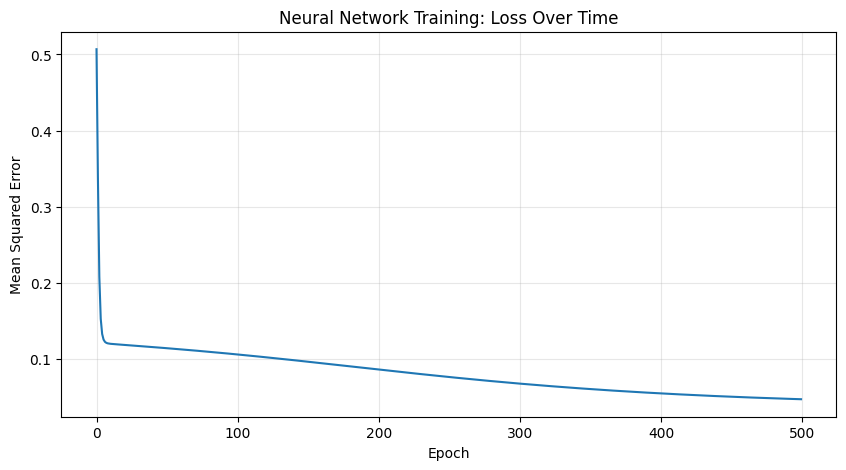


Final loss: 0.0474


In [33]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")

### 🎯 Exercise 2.2 (Intermediate): Digital Twin Prediction

**Task**: Test the trained network on new scenarios and interpret results.

**Scenarios to test**:
1. Weekend evening (day=6, time=18, weather=0.8, mood=0.9)
2. Weekday morning (day=2, time=8, weather=0.3, mood=0.5)
3. Weekend with bad weather (day=5, time=14, weather=0.2, mood=0.6)

In [10]:
# YOUR CODE HERE
# Normalize inputs (scale to 0-1 range)
def normalize_input(day, time, weather, mood):
    return np.array([[day/7, time/24, weather, mood]])

# Test scenarios
scenarios = [
    ("Weekend evening, good weather", 6, 18, 0.8, 0.9),
    ("Weekday morning, poor weather", 2, 8, 0.3, 0.5),
    ("Weekend afternoon, bad weather", 5, 14, 0.2, 0.6),
]

# Make predictions and analyze
for name, day, time, weather, mood in scenarios:
    X_test = normalize_input(day, time, weather, mood)
    prediction = nn.predict(X_test)
    print(f"{name}")
    print(f"  Social activity probability: {prediction[0][0]:.2%}\n")

Weekend evening, good weather
  Social activity probability: 72.61%

Weekday morning, poor weather
  Social activity probability: 6.27%

Weekend afternoon, bad weather
  Social activity probability: 22.70%



### 🎯 Exercise 2.3 (Advanced): Improve the Digital Twin

**Task**: Enhance the neural network to make better predictions.

**Challenges**:
1. Add more training data with realistic patterns
2. Experiment with different network architectures (hidden layer size)
3. Try different learning rates
4. Add a second hidden layer
5. Create a visualization showing prediction accuracy

In [34]:
# YOUR CODE HERE
# Challenge: Create a better training dataset

def generate_realistic_data(n_samples=500):
    """
    Generate more realistic training data for digital twin.

    Pattern rules:
    - Social activity higher on weekends
    - Time of day matters (evening > morning)
    - Good weather increases probability
    - Good mood increases probability
    """
    # YOUR CODE HERE
    np.random.seed(42)


    day = np.random.randint(0, 7, n_samples)       # 0-6
    time = np.random.randint(0, 24, n_samples)     # 0-23
    weather = np.random.rand(n_samples)            # 0-1
    mood = np.random.rand(n_samples)                # 0-1

    X = np.column_stack([day / 7, time / 24, weather, mood])

    is_weekend = (day >= 5).astype(float)
    is_evening = ((time >= 17) & (time <= 22)).astype(float)

    score = (0.35 * is_weekend +
             0.20 * is_evening +
             0.25 * weather +
             0.20 * mood)

    y = score + np.random.randn(n_samples) * 0.1
    y = np.clip(y, 0, 1).reshape(-1, 1)

    return X, y

X_train2, y_train2 = generate_realistic_data(500)
# Test different architectures
architectures = [
    (4, 4, 1),   # Small
    (4, 8, 1),   # Medium (original)
    (4, 16, 1),  # Large
]

# Compare performance
results = {}
for input_size, hidden_size, output_size in architectures:
    print(f"\n--- Architecture: {hidden_size} hidden units ---")
    model = SimpleNeuralNetwork(input_size, hidden_size, output_size)
    model.train(X_train2, y_train2, epochs=500, learning_rate=0.5)
    final_loss = model.loss_history[-1]
    results[hidden_size] = final_loss
    print(f"Final loss: {final_loss:.4f}")

print("\nSummary:")
for hidden_size, loss in results.items():
    print(f"  Hidden size {hidden_size}: final loss = {loss:.4f}")


--- Architecture: 4 hidden units ---
Epoch 0, Loss: 0.2036
Epoch 100, Loss: 0.0401
Epoch 200, Loss: 0.0360
Epoch 300, Loss: 0.0312
Epoch 400, Loss: 0.0265
Final loss: 0.0229

--- Architecture: 8 hidden units ---
Epoch 0, Loss: 0.1006
Epoch 100, Loss: 0.0359
Epoch 200, Loss: 0.0299
Epoch 300, Loss: 0.0253
Epoch 400, Loss: 0.0224
Final loss: 0.0207

--- Architecture: 16 hidden units ---
Epoch 0, Loss: 0.0902
Epoch 100, Loss: 0.0296
Epoch 200, Loss: 0.0233
Epoch 300, Loss: 0.0205
Epoch 400, Loss: 0.0195
Final loss: 0.0192

Summary:
  Hidden size 4: final loss = 0.0229
  Hidden size 8: final loss = 0.0207
  Hidden size 16: final loss = 0.0192


---
## Part 3: Connecting to LLMs

How does this relate to Large Language Models?

### 3.1 From Activities to Words

LLMs work exactly like our activity predictor, but with words!

Given text: I love coding in Python because it is

Predicted next word probabilities:
  fun: 29.33%
  clear: 24.57%
  elegant: 16.34%
  simple: 14.60%
  easy: 8.87%
  powerful: 5.68%
  versatile: 0.61%


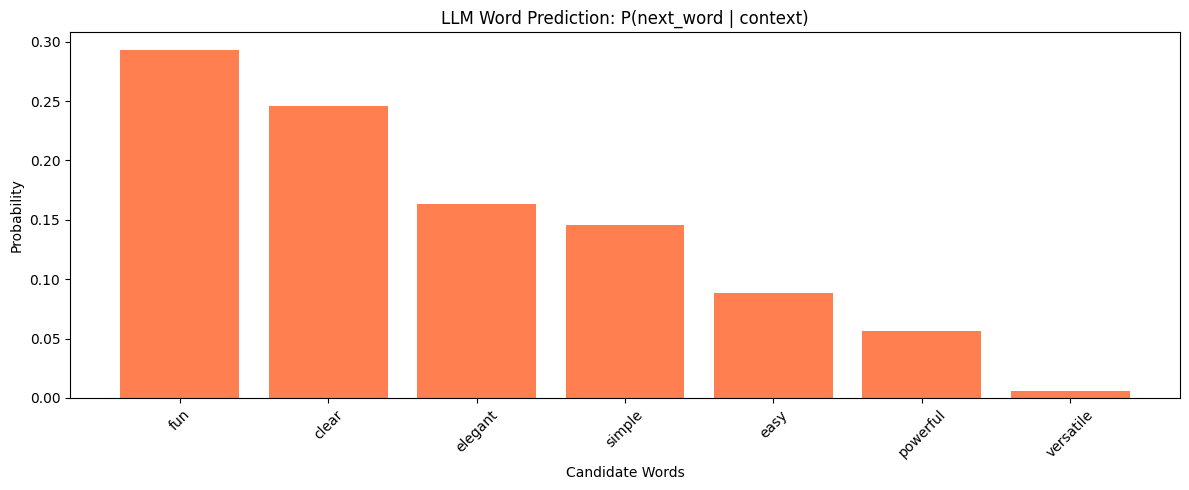

In [12]:
# Simple word prediction example
text_sequence = "I love coding in Python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'powerful', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum()  # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f"  {word}: {prob:.2%}")

# Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='coral')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Exercise 3.1 (Conceptual): Understanding LLMs

**Questions**:
1. How is predicting the next word similar to predicting the next activity?
2. What role does probability play in both cases?
3. Why might an LLM sometimes generate unexpected words?
4. How does context (previous words) help make better predictions?

Write your answers in the cell below:

**Your Answers:**

1. Similarity between word and activity prediction:
   -

2. Role of probability:
   -

3. Unexpected generations:
   -

4. Importance of context:
   -

---
## Summary & Key Takeaways

### What We Learned:
1. **Probability**: AI predicts by calculating probabilities based on historical patterns
2. **Conditional Probability**: Context matters - knowing what came before improves predictions
3. **Neural Networks**: Learn patterns by adjusting weights through training
4. **Digital Twin**: Can model behaviors using probabilistic predictions
5. **LLM Connection**: Language models are sophisticated versions of these basic concepts

### Next Steps:
In the next notebook, we'll explore:
- How LLMs represent words (embeddings)
- Transformer architecture
- Attention mechanisms
- Building a simple language model for your digital twin

---
## 🏆 Challenge Project (Advanced)

**Build Your Own Digital Twin Predictor**

Create a system that:
1. Collects data about your daily patterns (sleep, activities, mood, etc.)
2. Trains a neural network to predict your next likely activity
3. Evaluates prediction accuracy
4. Visualizes patterns it learned

**Bonus**: Add temporal features (day of week, time of day) and see how they improve predictions!

Sample of collected data:
  Day 0 (Weekday): Exercise, sleep=8.6h, mood=0.75, weather=0.06
  Day 1 (Weekday): Work, sleep=6.4h, mood=0.35, weather=0.12
  Day 2 (Weekday): Work, sleep=6.5h, mood=0.27, weather=0.04
  Day 3 (Weekday): Work, sleep=5.9h, mood=0.90, weather=0.11
  Day 4 (Weekday): Work, sleep=7.9h, mood=0.43, weather=0.23

Overall activity probabilities:
  Sleep: 16.67%
  Work: 45.00%
  Exercise: 20.00%
  Social: 11.67%
  Leisure: 6.67%

Training neural network WITH temporal features (day of week)...
  Epoch 0, Loss: 0.3176
  Epoch 200, Loss: 0.1295
  Epoch 400, Loss: 0.1216
  Epoch 600, Loss: 0.1180
  Epoch 800, Loss: 0.1160
Accuracy with day-of-week: 33.33%

Training neural network WITHOUT temporal features...
  Epoch 0, Loss: 0.2589
  Epoch 200, Loss: 0.1352
  Epoch 400, Loss: 0.1308
  Epoch 600, Loss: 0.1271
  Epoch 800, Loss: 0.1249
Accuracy without day-of-week: 25.00%

Bonus comparison: temporal features changed accuracy by +8.3 percentage points

Markov chain predicti

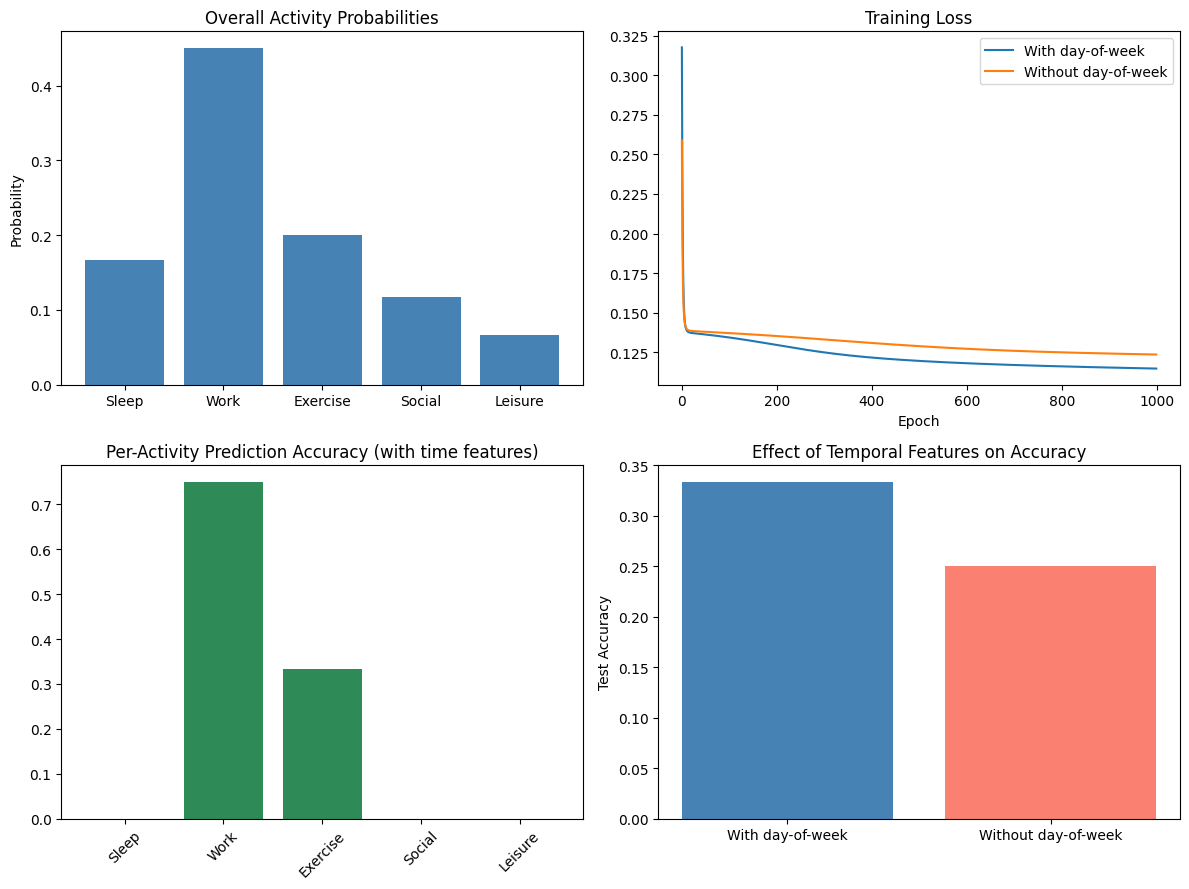

In [37]:
# YOUR CHALLENGE PROJECT CODE HERE
# This is your space to be creative!
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# ============================================================
# 1. COLLECT DATA
# ============================================================
np.random.seed(1)
n_days = 60

days_of_week = np.array([i % 7 for i in range(n_days)])
sleep_hours = np.random.normal(7, 1, n_days).clip(4, 10)
mood = np.random.rand(n_days)
weather = np.random.rand(n_days)

activities = []
for d in days_of_week:
    if d >= 5:
        activities.append(np.random.choice([2, 3, 4], p=[0.3, 0.4, 0.3]))
    else:
        activities.append(np.random.choice([1, 0, 2], p=[0.7, 0.2, 0.1]))
activities = np.array(activities)

print("Sample of collected data:")
for i in range(5):
    print(f"  Day {i} ({'Weekend' if days_of_week[i]>=5 else 'Weekday'}): "
          f"{activity_names[activities[i]]}, sleep={sleep_hours[i]:.1f}h, "
          f"mood={mood[i]:.2f}, weather={weather[i]:.2f}")


# ============================================================
# 2a. COMPONENT: Frequency probability (baseline model)
# ============================================================
def calculate_probabilities(sequence):
    counts = Counter(sequence)
    total = len(sequence)
    return {a: c/total for a, c in counts.items()}

freq_probs = calculate_probabilities(activities)
print("\nOverall activity probabilities:")
for a, p in sorted(freq_probs.items()):
    print(f"  {activity_names[a]}: {p:.2%}")


# ============================================================
# 2b. COMPONENT: Markov chain (conditional probability)
# ============================================================
def calculate_conditional_probabilities(sequence):
    transitions = {}
    for i in range(len(sequence) - 1):
        cur, nxt = sequence[i], sequence[i+1]
        transitions.setdefault(cur, []).append(nxt)
    return {cur: calculate_probabilities(nxt_list) for cur, nxt_list in transitions.items()}

def predict_next_markov(current, cond_probs):
    if current not in cond_probs:
        return None
    next_probs = cond_probs[current]
    return max(next_probs, key=next_probs.get)

cond_probs = calculate_conditional_probabilities(activities)


# ============================================================
# 2c. COMPONENT: Perceptron (single-feature decision)
# ============================================================
def perceptron(inputs, weights, bias):
    return sigmoid(np.dot(inputs, weights) + bias)

perceptron_weights = np.array([0.3, 0.5, 0.7])  # sleep, free_time, energy(=mood proxy)
perceptron_bias = -0.5


# ============================================================
# 2d. COMPONENT: Neural network (multi-feature, multi-class predictor)
# ============================================================
class SimpleNeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size):
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))
        self.loss_history = []

    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        m = X.shape[0]
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m
        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1, verbose=True):
        for epoch in range(epochs):
            output = self.forward(X)
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)
            self.backward(X, y, output, learning_rate)
            if verbose and epoch % 200 == 0:
                print(f"  Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        return self.forward(X)


def build_features_and_targets(activities, days_of_week, sleep_hours, mood, weather, include_time=True):
    X, y = [], []
    for i in range(len(activities) - 1):
        feats = [activities[i] / 4, sleep_hours[i] / 10, mood[i], weather[i]]
        if include_time:
            feats.insert(1, days_of_week[i] / 7)
        X.append(feats)
        target = np.zeros(5)
        target[activities[i + 1]] = 1
        y.append(target)
    return np.array(X), np.array(y)


# ============================================================
# ASSEMBLE: The Digital Twin
# ============================================================
class DigitalTwin:
    def __init__(self, activities, days_of_week, sleep_hours, mood, weather):
        self.activities = activities
        self.days_of_week = days_of_week
        self.sleep_hours = sleep_hours
        self.mood = mood
        self.weather = weather

        self.freq_probs = calculate_probabilities(activities)
        self.cond_probs = calculate_conditional_probabilities(activities)
        self.nn = None
        self.nn_no_time = None

    def markov_predict(self, current):
        return predict_next_markov(current, self.cond_probs)

    def perceptron_predict(self, sleep, free_time, energy):
        return perceptron(np.array([sleep, free_time, energy]), perceptron_weights, perceptron_bias)

    def train_nn(self, include_time=True, hidden_size=8, epochs=1000, learning_rate=0.3, verbose=True):
        X, y = build_features_and_targets(self.activities, self.days_of_week,
                                           self.sleep_hours, self.mood, self.weather,
                                           include_time=include_time)
        split = int(len(X) * 0.8)
        X_train, X_test = X[:split], X[split:]
        y_train, y_test = y[:split], y[split:]

        model = SimpleNeuralNetwork(input_size=X.shape[1], hidden_size=hidden_size, output_size=5)
        model.train(X_train, y_train, epochs=epochs, learning_rate=learning_rate, verbose=verbose)

        preds = np.argmax(model.predict(X_test), axis=1)
        actual = np.argmax(y_test, axis=1)
        accuracy = np.mean(preds == actual)

        if include_time:
            self.nn, self.nn_test = model, (X_test, y_test, preds, actual)
        else:
            self.nn_no_time = model

        return model, accuracy, preds, actual

    def simulate(self, start, days=7):
        seq = [start]
        for _ in range(days):
            nxt = self.markov_predict(seq[-1])
            if nxt is None:
                break
            seq.append(nxt)
        return seq


# ============================================================
# 3. TRAIN AND EVALUATE
# ============================================================
twin = DigitalTwin(activities, days_of_week, sleep_hours, mood, weather)

print("\nTraining neural network WITH temporal features (day of week)...")
model_time, acc_time, preds_time, actual_time = twin.train_nn(include_time=True)
print(f"Accuracy with day-of-week: {acc_time:.2%}")

print("\nTraining neural network WITHOUT temporal features...")
model_no_time, acc_no_time, preds_nt, actual_nt = twin.train_nn(include_time=False)
print(f"Accuracy without day-of-week: {acc_no_time:.2%}")

print(f"\nBonus comparison: temporal features changed accuracy by "
      f"{(acc_time - acc_no_time)*100:+.1f} percentage points")

print("\nMarkov chain prediction example:")
print(f"After Work: {activity_names[twin.markov_predict(1)]}")
print("7-day simulated sequence starting from Work:",
      [activity_names[a] for a in twin.simulate(1, days=7)])

print("\nPerceptron example (sleep=7, free_time=2, energy=0.8):")
print(f"  P(exercise) = {twin.perceptron_predict(7, 2, 0.8):.2%}")


# ============================================================
# 4. VISUALIZE
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Overall activity probabilities
acts = [activity_names[k] for k in sorted(twin.freq_probs.keys())]
probs = [twin.freq_probs[k] for k in sorted(twin.freq_probs.keys())]
axes[0, 0].bar(acts, probs, color='steelblue')
axes[0, 0].set_title("Overall Activity Probabilities")
axes[0, 0].set_ylabel("Probability")

# Training loss comparison
axes[0, 1].plot(model_time.loss_history, label="With day-of-week")
axes[0, 1].plot(model_no_time.loss_history, label="Without day-of-week")
axes[0, 1].set_title("Training Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].legend()

# Per-activity prediction accuracy
per_class_acc = [np.mean(preds_time[actual_time == c] == c) if np.any(actual_time == c) else 0
                  for c in range(5)]
axes[1, 0].bar([activity_names[c] for c in range(5)], per_class_acc, color='seagreen')
axes[1, 0].set_title("Per-Activity Prediction Accuracy (with time features)")
axes[1, 0].tick_params(axis='x', rotation=45)

# Accuracy comparison: with vs without temporal features
axes[1, 1].bar(["With day-of-week", "Without day-of-week"], [acc_time, acc_no_time],
               color=['steelblue', 'salmon'])
axes[1, 1].set_title("Effect of Temporal Features on Accuracy")
axes[1, 1].set_ylabel("Test Accuracy")

plt.tight_layout()
plt.show()